# Improved UCF101 Pose Action Recognition — BiLSTM + Temporal Attention

This notebook trains an improved temporal classifier from your **existing** sequence arrays in `data/processed/sequences_all/`. It does **not** rerun YOLO/ViTPose or rebuild sequences.

**Improvements**
- Bidirectional LSTM with temporal attention
- AdamW optimizer, label smoothing, gradient clipping
- Learning-rate reduction on validation-loss plateaus
- Early stopping based on validation macro-F1
- Best model saved separately from periodic recovery checkpoints
- CSV history and log file written every epoch

Run cells in order. Confirm that the train/validation/test arrays and labels match the schema from your current notebook before training.


In [1]:
from pathlib import Path
import copy, gc, json, logging, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score

PROJECT_DIR = Path(r"C:\Users\admin\ViTPose_Action_Recognition")
SEQUENCE_DIR = PROJECT_DIR / "data" / "processed" / "sequences_all"
OUTPUT_MODEL_DIR = PROJECT_DIR / "outputs" / "models"
OUTPUT_REPORT_DIR = PROJECT_DIR / "outputs" / "reports"
RECOVERY_DIR = OUTPUT_MODEL_DIR / "lstm_bilstm_attention_checkpoints"

for folder in (OUTPUT_MODEL_DIR, OUTPUT_REPORT_DIR, RECOVERY_DIR):
    folder.mkdir(parents=True, exist_ok=True)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Project:", PROJECT_DIR)
print("Sequence directory:", SEQUENCE_DIR)
print("PyTorch:", torch.__version__)
print("Device:", DEVICE)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

assert SEQUENCE_DIR.is_dir(), f"Sequence directory not found: {SEQUENCE_DIR}"


Project: C:\Users\admin\ViTPose_Action_Recognition
Sequence directory: C:\Users\admin\ViTPose_Action_Recognition\data\processed\sequences_all
PyTorch: 2.7.1+cu118
Device: cuda
GPU: NVIDIA RTX A4000


## 1. Load the existing split arrays

This expects `X_train.npy`, `X_val.npy`, `X_test.npy`, `y_train.npy`, `y_val.npy`, and `y_test.npy` in `sequences_all`. If your notebook stores these arrays under different names or paths, update this cell to match it. Arrays are loaded as memory maps to reduce RAM use.


In [2]:
# If your current notebook uses a different file naming scheme, edit these paths.
required_files = {
    "X_train": SEQUENCE_DIR / "X_train.npy",
    "X_val":   SEQUENCE_DIR / "X_val.npy",
    "X_test":  SEQUENCE_DIR / "X_test.npy",
    "y_train": SEQUENCE_DIR / "y_train.npy",
    "y_val":   SEQUENCE_DIR / "y_val.npy",
    "y_test":  SEQUENCE_DIR / "y_test.npy",
    "videos_train": SEQUENCE_DIR / "videos_train.npy",
    "videos_val":   SEQUENCE_DIR / "videos_val.npy",
    "videos_test":  SEQUENCE_DIR / "videos_test.npy",
}
missing = [str(p) for p in required_files.values() if not p.is_file()]
if missing:
    raise FileNotFoundError(
        "Missing expected array files:\n" + "\n".join(missing) +
        "\nOpen your original training notebook and adjust required_files to the actual filenames."
    )

X_train = np.load(required_files["X_train"], mmap_mode="r")
X_val   = np.load(required_files["X_val"], mmap_mode="r")
X_test  = np.load(required_files["X_test"], mmap_mode="r")
y_train = np.load(required_files["y_train"], mmap_mode="r")
y_val   = np.load(required_files["y_val"], mmap_mode="r")
y_test  = np.load(required_files["y_test"], mmap_mode="r")
videos_train = np.load(required_files["videos_train"], mmap_mode="r", allow_pickle=False)
videos_val = np.load(required_files["videos_val"], mmap_mode="r", allow_pickle=False)
videos_test = np.load(required_files["videos_test"], mmap_mode="r", allow_pickle=False)

print("Train:", X_train.shape, y_train.shape, "| source videos:", len(np.unique(videos_train)))
print("Validation:", X_val.shape, y_val.shape, "| source videos:", len(np.unique(videos_val)))
print("Test:", X_test.shape, y_test.shape, "| source videos:", len(np.unique(videos_test)))

assert X_train.ndim == X_val.ndim == X_test.ndim == 3
assert X_train.shape[1:] == X_val.shape[1:] == X_test.shape[1:]
assert X_train.shape[2] == 51, f"Expected 51 pose features, got {X_train.shape[2]}"
assert len(X_train) == len(y_train)
assert len(X_val) == len(y_val)
assert len(X_test) == len(y_test) == len(videos_test)

# Preserve the source-video split isolation checks from the original notebook.
train_video_set = set(np.unique(videos_train).tolist())
val_video_set = set(np.unique(videos_val).tolist())
test_video_set = set(np.unique(videos_test).tolist())
assert not train_video_set & val_video_set, "Source-video leakage: train/validation overlap."
assert not train_video_set & test_video_set, "Source-video leakage: train/test overlap."
assert not val_video_set & test_video_set, "Source-video leakage: validation/test overlap."
print("No source-video leakage detected.")

# Class IDs must be consecutive integers from 0 through NUM_CLASSES-1.
all_train_classes = np.unique(np.asarray(y_train))
NUM_CLASSES = int(max(np.max(y_train), np.max(y_val), np.max(y_test))) + 1
assert np.array_equal(all_train_classes, np.arange(NUM_CLASSES)), (
    "Training labels must contain every class ID from 0 to NUM_CLASSES-1."
)
INPUT_SIZE = int(X_train.shape[2])
SEQUENCE_LENGTH = int(X_train.shape[1])
print("Classes:", NUM_CLASSES, "| Sequence length:", SEQUENCE_LENGTH, "| Input size:", INPUT_SIZE)


Train: (63533, 16, 51) (63533,) | source videos: 7256
Validation: (20980, 16, 51) (20980,) | source videos: 2428
Test: (21009, 16, 51) (21009,) | source videos: 2441
No source-video leakage detected.
Classes: 101 | Sequence length: 16 | Input size: 51


## 2. Class names and data loaders

If your labels use class IDs from a saved `label_map`, load that mapping here so the checkpoint preserves it. The classifier itself only needs numeric labels.


In [3]:
# Optional: load a saved label mapping if your sequence folder has one.
# Expected mapping examples:
# {"ApplyEyeMakeup": 0, "ApplyLipstick": 1, ...}
label_map_path = SEQUENCE_DIR / "label_map.json"
label_map = None
if label_map_path.is_file():
    with open(label_map_path, "r", encoding="utf-8") as f:
        label_map = json.load(f)
else:
    label_map = {str(i): i for i in range(NUM_CLASSES)}
print("Label mapping loaded:", label_map_path.is_file())

BATCH_SIZE = 8
NUM_WORKERS = 0

class PoseSequenceDataset(Dataset):
    def __init__(self, X, y):
        self.X, self.y = X, y
    def __len__(self):
        return len(self.y)
    def __getitem__(self, idx):
        x = np.array(self.X[idx], dtype=np.float32, copy=True)
        y = int(self.y[idx])
        return torch.from_numpy(x), torch.tensor(y, dtype=torch.long)

train_loader = DataLoader(
    PoseSequenceDataset(X_train, y_train), batch_size=BATCH_SIZE,
    shuffle=True, num_workers=NUM_WORKERS, pin_memory=(DEVICE.type == "cuda")
)
val_loader = DataLoader(
    PoseSequenceDataset(X_val, y_val), batch_size=BATCH_SIZE,
    shuffle=False, num_workers=NUM_WORKERS, pin_memory=(DEVICE.type == "cuda")
)
print("Train batches:", len(train_loader), "| Validation batches:", len(val_loader))


Label mapping loaded: True
Train batches: 7942 | Validation batches: 2623


## 3. Define the Bidirectional LSTM with temporal attention

In [4]:
class PoseLSTM(nn.Module):
    def __init__(self, input_size, hidden_size, num_layers, num_classes, dropout):
        super().__init__()
        self.input_norm = nn.LayerNorm(input_size)
        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            bidirectional=True,
            dropout=dropout if num_layers > 1 else 0.0,
        )
        self.attention = nn.Sequential(
            nn.Linear(hidden_size * 2, hidden_size),
            nn.Tanh(),
            nn.Linear(hidden_size, 1),
        )
        self.classifier = nn.Sequential(
            nn.LayerNorm(hidden_size * 2),
            nn.Dropout(dropout),
            nn.Linear(hidden_size * 2, num_classes),
        )

    def forward(self, x):
        x = self.input_norm(x)
        sequence_output, _ = self.lstm(x)
        scores = self.attention(sequence_output).squeeze(-1)
        weights = torch.softmax(scores, dim=1)
        context = torch.sum(sequence_output * weights.unsqueeze(-1), dim=1)
        return self.classifier(context)

HIDDEN_SIZE = 128
NUM_LAYERS = 2
DROPOUT = 0.35
LEARNING_RATE = 5e-4
WEIGHT_DECAY = 1e-3
MAX_EPOCHS = 100
PATIENCE = 12
SAVE_EVERY = 5

model = PoseLSTM(
    INPUT_SIZE, HIDDEN_SIZE, NUM_LAYERS, NUM_CLASSES, DROPOUT
).to(DEVICE)

train_counts = np.bincount(np.asarray(y_train, dtype=np.int64), minlength=NUM_CLASSES).astype(np.float64)
assert np.all(train_counts > 0), "At least one class has no training examples."
class_weights = 1.0 / np.sqrt(train_counts)
class_weights /= class_weights.mean()
criterion = nn.CrossEntropyLoss(
    weight=torch.tensor(class_weights, dtype=torch.float32, device=DEVICE),
    label_smoothing=0.05,
)
optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode="min", factor=0.5, patience=3, min_lr=1e-6
)

print(model)


PoseLSTM(
  (input_norm): LayerNorm((51,), eps=1e-05, elementwise_affine=True)
  (lstm): LSTM(51, 128, num_layers=2, batch_first=True, dropout=0.35, bidirectional=True)
  (attention): Sequential(
    (0): Linear(in_features=256, out_features=128, bias=True)
    (1): Tanh()
    (2): Linear(in_features=128, out_features=1, bias=True)
  )
  (classifier): Sequential(
    (0): LayerNorm((256,), eps=1e-05, elementwise_affine=True)
    (1): Dropout(p=0.35, inplace=False)
    (2): Linear(in_features=256, out_features=101, bias=True)
  )
)


## 4. Train with per-epoch logging and recovery checkpoints

The best model is chosen using **validation macro-F1**. Recovery checkpoints are saved every five epochs. Training history is written after each epoch, so the log remains useful if the notebook stops unexpectedly. Recovery files are saved for recovery, but this notebook does not automatically resume training from them.


In [6]:
MODEL_PATH = OUTPUT_MODEL_DIR / "lstm_bilstm_attention_best.pt"
HISTORY_PATH = OUTPUT_REPORT_DIR / "lstm_bilstm_attention_history.csv"
LOG_PATH = OUTPUT_REPORT_DIR / "lstm_bilstm_attention_training.log"

logger = logging.getLogger("improved_lstm")
logger.setLevel(logging.INFO)
logger.handlers.clear()
logger.propagate = False
formatter = logging.Formatter("%(asctime)s | %(levelname)s | %(message)s")
file_handler = logging.FileHandler(LOG_PATH, encoding="utf-8")
file_handler.setFormatter(formatter)
logger.addHandler(file_handler)

def run_epoch(model, loader, training):
    model.train(training)
    total_loss, total_count = 0.0, 0
    truths, predictions = [], []
    with torch.set_grad_enabled(training):
        for xb, yb in loader:
            xb = xb.to(DEVICE, non_blocking=(DEVICE.type == "cuda"))
            yb = yb.to(DEVICE, non_blocking=(DEVICE.type == "cuda"))
            if training:
                optimizer.zero_grad(set_to_none=True)
            logits = model(xb)
            loss = criterion(logits, yb)
            if training:
                loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
                optimizer.step()
            total_loss += loss.item() * len(yb)
            total_count += len(yb)
            truths.append(yb.detach().cpu().numpy())
            predictions.append(logits.detach().argmax(dim=1).cpu().numpy())

    y_true = np.concatenate(truths)
    y_pred = np.concatenate(predictions)
    return {
        "loss": total_loss / max(total_count, 1),
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_f1": f1_score(
            y_true, y_pred, labels=list(range(NUM_CLASSES)),
            average="macro", zero_division=0
        ),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
    }

history = []
best_val_f1, best_val_loss, best_epoch = -1.0, float("inf"), 0
epochs_without_improvement = 0

logger.info("Training started on %s", DEVICE)
logger.info("Train=%d Validation=%d Classes=%d", len(y_train), len(y_val), NUM_CLASSES)

for epoch in range(1, MAX_EPOCHS + 1):
    train_m = run_epoch(model, train_loader, training=True)
    val_m = run_epoch(model, val_loader, training=False)
    scheduler.step(val_m["loss"])
    lr = optimizer.param_groups[0]["lr"]

    row = {
        "epoch": epoch, "learning_rate": lr,
        "train_loss": train_m["loss"],
        "train_accuracy": train_m["accuracy"],
        "train_macro_f1": train_m["macro_f1"],
        "train_balanced_accuracy": train_m["balanced_accuracy"],
        "val_loss": val_m["loss"],
        "val_accuracy": val_m["accuracy"],
        "val_macro_f1": val_m["macro_f1"],
        "val_balanced_accuracy": val_m["balanced_accuracy"],
    }
    history.append(row)
    msg = (
        f"Epoch {epoch:03d}/{MAX_EPOCHS} lr={lr:.2e} | "
        f"train loss={row['train_loss']:.4f} acc={row['train_accuracy']:.4f} "
        f"F1={row['train_macro_f1']:.4f} | "
        f"val loss={row['val_loss']:.4f} acc={row['val_accuracy']:.4f} "
        f"F1={row['val_macro_f1']:.4f}"
    )
    print(msg, flush=True)
    logger.info(msg)
    pd.DataFrame(history).to_csv(HISTORY_PATH, index=False)

    improved = (
        row["val_macro_f1"] > best_val_f1 + 1e-6
        or (abs(row["val_macro_f1"] - best_val_f1) <= 1e-6
            and row["val_loss"] < best_val_loss)
    )
    if improved:
        best_val_f1, best_val_loss, best_epoch = row["val_macro_f1"], row["val_loss"], epoch
        epochs_without_improvement = 0
        torch.save({
            "model_state": copy.deepcopy(model.state_dict()),
            "input_size": INPUT_SIZE,
            "sequence_length": SEQUENCE_LENGTH,
            "hidden_size": HIDDEN_SIZE,
            "num_layers": NUM_LAYERS,
            "dropout": DROPOUT,
            "num_classes": NUM_CLASSES,
            "label_map": label_map,
            "best_epoch": best_epoch,
            "best_val_macro_f1": best_val_f1,
            "best_val_loss": best_val_loss,
            "architecture": "bidirectional_lstm_temporal_attention",
        }, MODEL_PATH)
        logger.info("Saved best model at epoch %d", epoch)
    else:
        epochs_without_improvement += 1

    if epoch % SAVE_EVERY == 0:
        recovery_path = RECOVERY_DIR / f"epoch_{epoch:03d}.pt"
        torch.save({
            "epoch": epoch,
            "model_state": model.state_dict(),
            "optimizer_state": optimizer.state_dict(),
            "scheduler_state": scheduler.state_dict(),
            "history": history,
            "best_epoch": best_epoch,
            "best_val_macro_f1": best_val_f1,
            "epochs_without_improvement": epochs_without_improvement,
        }, recovery_path)
        logger.info("Saved recovery checkpoint %s", recovery_path.name)

    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()
    gc.collect()

    if epochs_without_improvement >= PATIENCE:
        logger.info("Early stopping at epoch %d; best epoch=%d", epoch, best_epoch)
        print(f"Early stopping at epoch {epoch}. Best epoch: {best_epoch}")
        break

assert MODEL_PATH.is_file(), "No best checkpoint was saved."
print("\nTraining complete.")
print("Best epoch:", best_epoch)
print("Best validation macro-F1:", round(best_val_f1, 4))
print("Best model:", MODEL_PATH)
print("History:", HISTORY_PATH)
print("Log:", LOG_PATH)
print("Recovery directory:", RECOVERY_DIR)


Epoch 001/100 lr=1.25e-04 | train loss=0.5938 acc=0.9947 F1=0.9919 | val loss=1.9257 acc=0.7010 F1=0.6183
Epoch 002/100 lr=1.25e-04 | train loss=0.5902 acc=0.9946 F1=0.9912 | val loss=1.9472 acc=0.7014 F1=0.6210
Epoch 003/100 lr=6.25e-05 | train loss=0.5882 acc=0.9945 F1=0.9922 | val loss=1.9923 acc=0.6940 F1=0.6165
Epoch 004/100 lr=6.25e-05 | train loss=0.5773 acc=0.9962 F1=0.9944 | val loss=1.9838 acc=0.6988 F1=0.6178
Epoch 005/100 lr=6.25e-05 | train loss=0.5747 acc=0.9968 F1=0.9944 | val loss=2.0010 acc=0.6977 F1=0.6189
Epoch 006/100 lr=6.25e-05 | train loss=0.5733 acc=0.9968 F1=0.9953 | val loss=2.0201 acc=0.6952 F1=0.6141
Epoch 007/100 lr=3.13e-05 | train loss=0.5706 acc=0.9972 F1=0.9957 | val loss=2.0305 acc=0.6944 F1=0.6144
Epoch 008/100 lr=3.13e-05 | train loss=0.5659 acc=0.9979 F1=0.9970 | val loss=2.0322 acc=0.6956 F1=0.6140
Epoch 009/100 lr=3.13e-05 | train loss=0.5643 acc=0.9979 F1=0.9971 | val loss=2.0485 acc=0.6937 F1=0.6151
Epoch 010/100 lr=3.13e-05 | train loss=0.5639 

## 5. Plot learning curves

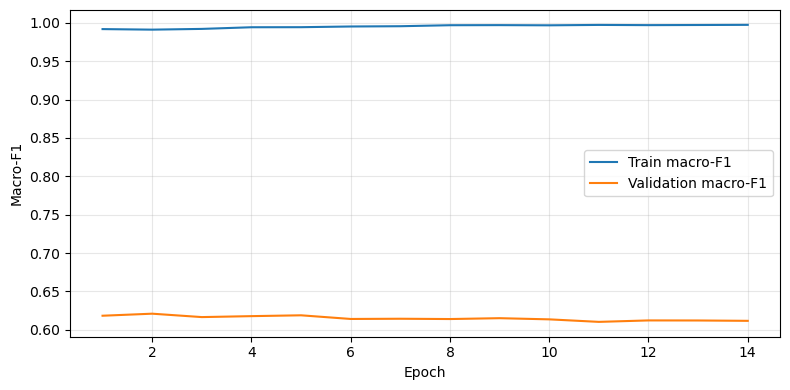

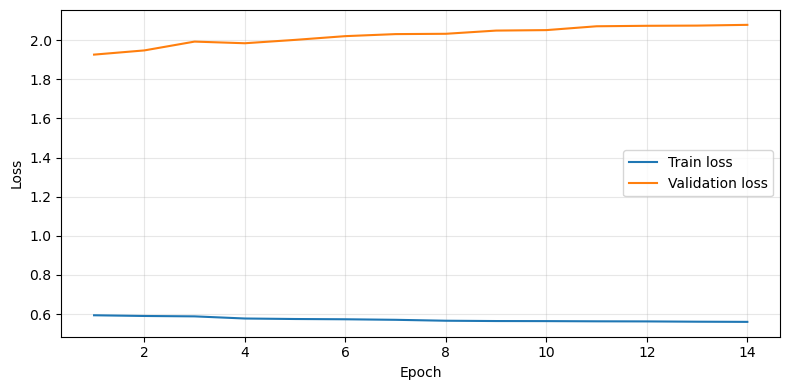

In [7]:
hist = pd.read_csv(HISTORY_PATH)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(hist["epoch"], hist["train_macro_f1"], label="Train macro-F1")
ax.plot(hist["epoch"], hist["val_macro_f1"], label="Validation macro-F1")
ax.set_xlabel("Epoch")
ax.set_ylabel("Macro-F1")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(hist["epoch"], hist["train_loss"], label="Train loss")
ax.plot(hist["epoch"], hist["val_loss"], label="Validation loss")
ax.set_xlabel("Epoch")
ax.set_ylabel("Loss")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


## 6. Evaluate the best checkpoint on the held-out test set

Run this once after model selection. Do not tune hyperparameters based on repeated test-set comparisons. The test set is evaluated only with the best validation checkpoint.


In [8]:
checkpoint = torch.load(MODEL_PATH, map_location=DEVICE)
best_model = PoseLSTM(
    input_size=checkpoint["input_size"],
    hidden_size=checkpoint["hidden_size"],
    num_layers=checkpoint["num_layers"],
    num_classes=checkpoint["num_classes"],
    dropout=checkpoint["dropout"],
).to(DEVICE)
best_model.load_state_dict(checkpoint["model_state"])
best_model.eval()

test_loader = DataLoader(
    PoseSequenceDataset(X_test, y_test), batch_size=BATCH_SIZE,
    shuffle=False, num_workers=NUM_WORKERS,
    pin_memory=(DEVICE.type == "cuda")
)

test_truths, test_preds = [], []
with torch.no_grad():
    for xb, yb in test_loader:
        xb = xb.to(DEVICE, non_blocking=(DEVICE.type == "cuda"))
        logits = best_model(xb)
        test_preds.append(logits.argmax(dim=1).cpu().numpy())
        test_truths.append(yb.numpy())

y_true = np.concatenate(test_truths)
y_pred = np.concatenate(test_preds)

test_metrics = {
    "best_epoch": int(checkpoint["best_epoch"]),
    "best_validation_macro_f1": float(checkpoint["best_val_macro_f1"]),
    "test_accuracy": float(accuracy_score(y_true, y_pred)),
    "test_balanced_accuracy": float(balanced_accuracy_score(y_true, y_pred)),
    "test_macro_f1": float(f1_score(
        y_true, y_pred, labels=list(range(NUM_CLASSES)),
        average="macro", zero_division=0
    )),
    "test_samples": int(len(y_true)),
}
metrics_path = OUTPUT_REPORT_DIR / "lstm_bilstm_attention_test_metrics.json"
with open(metrics_path, "w", encoding="utf-8") as f:
    json.dump(test_metrics, f, indent=2)

print(json.dumps(test_metrics, indent=2))
print("Saved metrics:", metrics_path)


{
  "best_epoch": 2,
  "best_validation_macro_f1": 0.6209761017944422,
  "test_accuracy": 0.6854681327050312,
  "test_balanced_accuracy": 0.6079628504853151,
  "test_macro_f1": 0.6096203494411987,
  "test_samples": 21009
}
Saved metrics: C:\Users\admin\ViTPose_Action_Recognition\outputs\reports\lstm_bilstm_attention_test_metrics.json
